# Fase 4 — Modelado analítico: Clustering, PCA, Clasificación y LDA
Este notebook responde las hipótesis formuladas en el EDA:

| # | Pregunta de negocio | Técnica |
|---|---|---|
| H1 | ¿Qué **tipos de jornada operativa** tiene la planta? | Clustering (K-means) sobre perfiles diarios |
| H3 | ¿Cuántas dimensiones resumen la forma de un día de operación? | PCA sobre perfiles diarios |
| H2 | ¿Podemos **anticipar con una hora de antelación** la severidad del exceso de energía reactiva? | Clasificación (comparación de 4 modelos + línea base) |
| H4 | ¿Una reducción supervisada a 2 ejes conserva o mejora la clasificación? | LDA |

El orden sigue la lógica del análisis: primero entendemos la operación diaria (clustering y PCA) y después construimos la herramienta predictiva (clasificación y LDA).

## 0. Configuración
Librería principal: **scikit-learn** (`sklearn`), el estándar en Python para aprendizaje automático. Todas sus herramientas siguen el mismo patrón: se crea el objeto, se entrena con `.fit()` y se usa con `.predict()` o `.transform()`.

**Reproducibilidad:** todos los procesos aleatorios (K-means, Random Forest) reciben `random_state=SEMILLA`. Si ejecutan el notebook otra vez, obtendrán exactamente los mismos resultados.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (silhouette_score, adjusted_rand_score, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.inspection import permutation_importance

SEMILLA = 42
np.random.seed(SEMILLA)
pd.set_option("display.width", 200)

BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RUTA_PROC = BASE / "data" / "processed"
RUTA_FIG = BASE / "reports" / "figures"
RUTA_TABLAS = BASE / "reports" / "tablas"

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#8a8986", "axes.titleweight": "bold", "axes.titlesize": 11})
PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # azul, naranja, aguamarina, amarillo
def guardar(fig, nombre):
    fig.savefig(RUTA_FIG / f"{nombre}.png", bbox_inches="tight")

df = pd.read_csv(RUTA_PROC / "consumo_15min_limpio.csv", parse_dates=["ts_inicio", "fecha"])
horaria = pd.read_csv(RUTA_PROC / "consumo_horario.csv", parse_dates=["ts_inicio"])
diaria = pd.read_csv(RUTA_PROC / "consumo_diario.csv", parse_dates=["fecha"])
print(df.shape, horaria.shape, diaria.shape)

(35040, 24) (8760, 8) (365, 14)


---
## PARTE A. Clustering: tipos de jornada operativa (H1)
### A.1 ¿Qué agrupamos y por qué?
**Unidad de análisis:** cada **día** del año (365 días). **Variables:** la energía consumida en cada una de las 24 horas del día (el **perfil horario**). Así, cada día es un vector de 24 números, y dos días son "parecidos" si consumen de forma similar a lo largo de las horas.

**¿Por qué días y no intervalos de 15 minutos?** Porque la decisión de gestión (planificar turnos, presupuestar energía) se toma por **jornada**. Agrupar intervalos sueltos solo separaría "consumo alto" de "consumo bajo", algo que ya sabemos.

**Algoritmo: K-means.** Divide los datos en *k* grupos y asigna cada día al grupo cuyo **centroide** (perfil promedio) está más cerca. Lo elegimos porque es simple, rápido e interpretable: cada centroide **es** un perfil de consumo típico. DBSCAN requiere calibrar dos parámetros de densidad poco intuitivos en 24 dimensiones; el jerárquico lo usaremos como **verificación de robustez**.

**Estandarización:** con `StandardScaler` cada hora queda con media 0 y desviación 1. Sin esto, las horas de producción (valores grandes) dominarían la distancia y las horas nocturnas (valores pequeños) no contarían. Así detectamos, por ejemplo, días con operación nocturna.

In [2]:
perfiles = df.pivot_table(index="fecha", columns="hora", values="energia_kwh", aggfunc="sum")
print("Matriz de perfiles diarios:", perfiles.shape, "(días × horas)")
escalador_dias = StandardScaler()
X_dias = escalador_dias.fit_transform(perfiles)
perfiles.iloc[:3, :12].round(1)

Matriz de perfiles diarios: (365, 24) (días × horas)


hora,0,1,2,3,4,5,6,7,8,9,10,11
fecha,,,,,,,,,,,,
2018-01-01,13.7,14.3,13.8,14.5,13.9,14.2,13.8,13.6,14.4,15.2,15.6,14.4
2018-01-02,13.7,14.4,13.8,14.4,13.8,14.0,13.9,22.6,183.5,209.0,265.8,487.2
2018-01-03,18.4,18.5,18.5,18.5,18.3,18.2,18.4,28.1,326.2,364.8,274.9,279.4


### A.2 Elección de *k*: método del codo y coeficiente de silueta
- **Inercia (método del codo):** suma de distancias de cada día a su centroide. Siempre baja al aumentar *k*; buscamos el "codo", donde deja de bajar mucho.
- **Silueta:** para cada día compara qué tan cerca está de su propio grupo frente al grupo vecino. Va de −1 a 1; **más alto = grupos más compactos y separados**. Es el criterio principal.

`n_init=20` ejecuta K-means 20 veces con puntos de partida distintos y se queda con la mejor solución (evita mínimos locales).

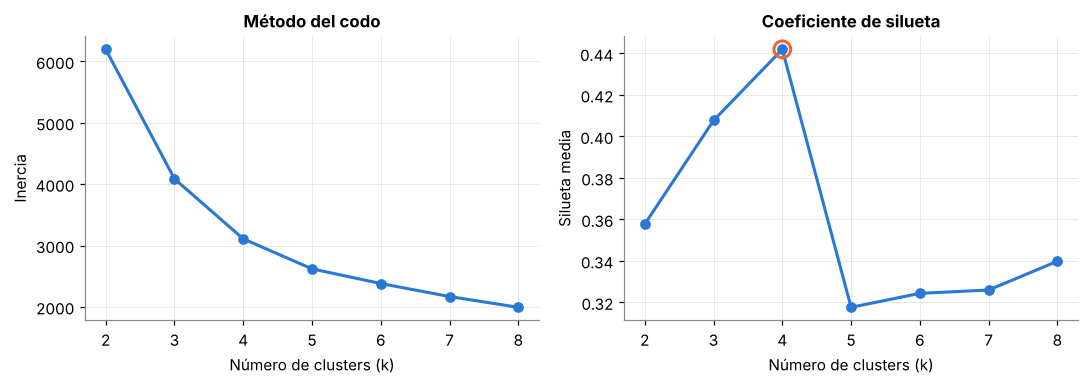

,k,inercia,silueta
0,2,6197.613,0.358
1,3,4087.119,0.408
2,4,3109.440,0.442
3,5,2620.594,0.318
4,6,2381.291,0.324
5,7,2169.575,0.326
6,8,1993.651,0.340


In [3]:
res_k = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEMILLA).fit(X_dias)
    res_k.append({"k": k, "inercia": km.inertia_, "silueta": silhouette_score(X_dias, km.labels_)})
res_k = pd.DataFrame(res_k)
res_k.round(3).to_csv(RUTA_TABLAS / "clustering_eleccion_k.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(res_k["k"], res_k["inercia"], marker="o", color=PALETA[0], lw=2)
axes[0].set(title="Método del codo", xlabel="Número de clusters (k)", ylabel="Inercia")
axes[1].plot(res_k["k"], res_k["silueta"], marker="o", color=PALETA[0], lw=2)
k_opt = int(res_k.loc[res_k["silueta"].idxmax(), "k"])
axes[1].scatter([k_opt], [res_k["silueta"].max()], s=120, facecolors="none", edgecolors=PALETA[1], lw=2, zorder=3)
axes[1].set(title="Coeficiente de silueta", xlabel="Número de clusters (k)", ylabel="Silueta media")
fig.tight_layout(); guardar(fig, "fig09_eleccion_k"); plt.show()
res_k.round(3)

**Decisión: k = 4.** La silueta alcanza su **máximo** en k = 4 (≈0,44) y cae claramente con k = 5 (≈0,32). En la curva del codo, la reducción de inercia se vuelve pequeña a partir de k = 4. Ambos criterios coinciden.

### A.3 Ajuste final y perfil de cada cluster
Asignamos nombres de negocio de forma **automática y reproducible**, según las características de cada centroide (no a mano):
- el de menor energía → **Sin producción / reposo**;
- de los restantes, el de mayor consumo nocturno (0–6 h) → **Operación continua 24 h**;
- de los restantes, el de mayor consumo entre las 21 y 23 h → **Jornada extendida**;
- el último → **Jornada estándar**.

In [4]:
kmeans = KMeans(n_clusters=4, n_init=20, random_state=SEMILLA).fit(X_dias)
etq = pd.Series(kmeans.labels_, index=perfiles.index)
prom = perfiles.groupby(etq.values).mean()
energia_c = prom.sum(axis=1)
restantes = list(prom.index)
nombres = {}
c = energia_c.idxmin(); nombres[c] = "Sin producción / reposo"; restantes.remove(c)
c = prom.loc[restantes, range(0, 7)].sum(axis=1).idxmax(); nombres[c] = "Operación continua 24 h"; restantes.remove(c)
c = prom.loc[restantes, [21, 22, 23]].sum(axis=1).idxmax(); nombres[c] = "Jornada extendida"; restantes.remove(c)
nombres[restantes[0]] = "Jornada estándar"
ORDEN_CL = ["Jornada estándar", "Jornada extendida", "Operación continua 24 h", "Sin producción / reposo"]
COLOR_CL = dict(zip(ORDEN_CL, PALETA))

diaria["cluster"] = etq.map(nombres).reindex(diaria["fecha"]).values
energia_max = df[df["tipo_carga"] == "Maximum_Load"].groupby("fecha")["energia_kwh"].sum()
diaria["energia_periodo_max_kwh"] = energia_max.reindex(diaria["fecha"]).fillna(0).values
perfil_cl = diaria.groupby("cluster").agg(
    dias=("fecha", "size"),
    energia_media_kwh=("energia_kwh", "mean"),
    demanda_pico_kw=("demanda_pico_kw", "mean"),
    factor_carga=("factor_carga", "mean"),
    fp_dia_pct=("fp_dia_pct", "mean"),
    pct_tiempo_fp_bajo=("pct_tiempo_fp_bajo", "mean"),
    exceso_reactiva_kvarh=("exceso_reactiva_kvarh", "mean"),
    pct_domingos=("dia_semana", lambda s: (s == "Sunday").mean() * 100),
    pct_sabados=("dia_semana", lambda s: (s == "Saturday").mean() * 100),
).reindex(ORDEN_CL)
perfil_cl["pct_energia_anual"] = diaria.groupby("cluster")["energia_kwh"].sum().reindex(ORDEN_CL) / diaria["energia_kwh"].sum() * 100
perfil_cl["pct_energia_en_punta"] = (diaria.groupby("cluster")["energia_periodo_max_kwh"].sum() / diaria.groupby("cluster")["energia_kwh"].sum()).reindex(ORDEN_CL) * 100
perfil_cl = perfil_cl.round(2)
perfil_cl.to_csv(RUTA_TABLAS / "clustering_perfiles.csv")
perfil_cl

,dias,energia_media_kwh,demanda_pico_kw,factor_carga,fp_dia_pct,pct_tiempo_fp_bajo,exceso_reactiva_kvarh,pct_domingos,pct_sabados,pct_energia_anual,pct_energia_en_punta
cluster,,,,,,,,,,,
Jornada estándar,236,3184.09,428.34,0.32,89.56,59.88,239.35,2.12,4.24,78.30,47.43
Jornada extendida,17,5114.19,517.58,0.41,92.66,50.19,179.60,0.00,5.88,9.06,36.28
Operación continua 24 h,7,5955.01,463.49,0.54,90.89,48.96,336.21,0.00,14.29,4.34,30.15
Sin producción / reposo,105,757.79,116.07,0.51,88.75,44.60,130.71,44.76,38.10,8.29,38.30


In [5]:
for c in ORDEN_CL:
    fechas = diaria.loc[diaria["cluster"] == c, "fecha"]
    meses = fechas.dt.month.value_counts().sort_index()
    print(f"{c:26s} meses (n.º de días): {dict(meses)}")

Jornada estándar           meses (n.º de días): {1: np.int64(14), 2: np.int64(6), 3: np.int64(22), 4: np.int64(23), 5: np.int64(22), 6: np.int64(20), 7: np.int64(25), 8: np.int64(22), 9: np.int64(15), 10: np.int64(24), 11: np.int64(24), 12: np.int64(19)}
Jornada extendida          meses (n.º de días): {1: np.int64(3), 2: np.int64(13), 10: np.int64(1)}
Operación continua 24 h    meses (n.º de días): {1: np.int64(7)}
Sin producción / reposo    meses (n.º de días): {1: np.int64(7), 2: np.int64(9), 3: np.int64(9), 4: np.int64(7), 5: np.int64(9), 6: np.int64(10), 7: np.int64(6), 8: np.int64(9), 9: np.int64(15), 10: np.int64(6), 11: np.int64(6), 12: np.int64(12)}


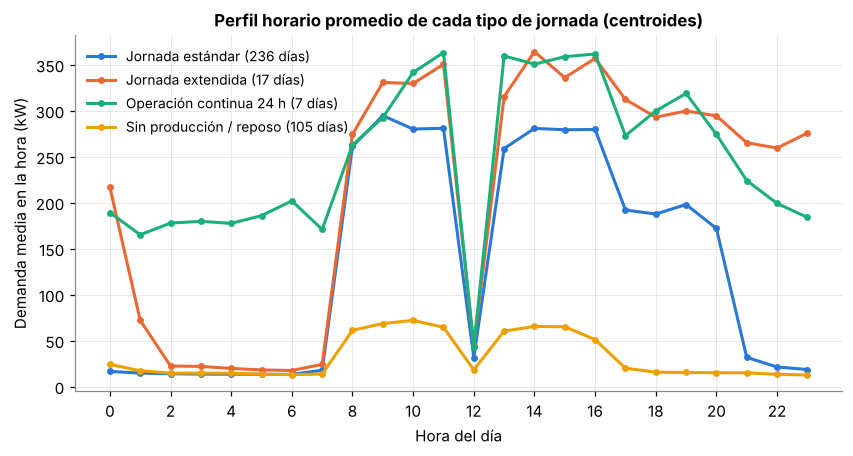

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for c in ORDEN_CL:
    p = perfiles.loc[etq.map(nombres) == c].mean() * 1  # kWh en la hora = kW medios
    n = (etq.map(nombres) == c).sum()
    ax.plot(p.index, p.values, lw=2, marker="o", ms=3.5, color=COLOR_CL[c], label=f"{c} ({n} días)")
ax.set(title="Perfil horario promedio de cada tipo de jornada (centroides)", xlabel="Hora del día",
       ylabel="Demanda media en la hora (kW)", xticks=range(0, 24, 2))
ax.legend(frameon=False, fontsize=9)
guardar(fig, "fig10_perfiles_clusters"); plt.show()

**Interpretación de los clusters (significado de negocio):**

| Cluster | ¿Qué es? | Rasgos (ver tabla) |
|---|---|---|
| **Jornada estándar** | La operación normal: dos turnos diurnos (8–21 h), pausa a mediodía y reposo nocturno. | Es la gran mayoría de los días laborables y concentra la mayor parte de la energía anual. Factor de carga bajo (~0,32): picos marcados. |
| **Jornada extendida** | Días en que la producción se prolonga hasta la medianoche. | Mayor energía y pico que la estándar. Ocurre casi solo en enero y febrero (más un día de octubre): son **picos de demanda de producción**. |
| **Operación continua 24 h** | La planta trabaja también de madrugada. | Solo 7 días de enero (18 al 26). Es la jornada de mayor energía y con **mejor factor de carga** (~0,54): la planta está cargada todo el día. |
| **Sin producción / reposo** | Domingos, la mayoría de sábados y feriados (p. ej., Año Nuevo Lunar a mediados de febrero). | ~4 veces menos energía que la jornada estándar y el **peor FP diario** (~88,8 %): la carga base consume reactiva sin producir. |

**Dato de gestión:** la **jornada estándar** es la que tiene mayor proporción del tiempo con FP < 90 % (~60 %) y, al sumar 236 días, concentra la mayor parte de la reactiva excedente del año. Ahí debe enfocarse la compensación.

**Conclusión H1: se acepta.** Los días se agrupan en **4 tipos de jornada** claramente diferenciados y con significado operativo. **Uso en gestión:** presupuestar la energía y la compensación de reactiva **según el tipo de jornada programada**. Por ejemplo, las jornadas extendidas y continuas de enero explican por qué ese mes consume 2,2 veces más que septiembre.

### A.4 Validación de robustez del clustering
Un buen agrupamiento no debe depender del azar ni del algoritmo. Lo comprobamos de dos formas con el **Índice de Rand Ajustado (ARI)**: mide la concordancia entre dos agrupaciones (1 = idénticas; 0 = coincidencia al azar).
1. **Estabilidad:** repetimos K-means con 10 semillas distintas y comparamos con la solución final.
2. **Otro algoritmo:** aplicamos **clustering jerárquico (método de Ward)**, que funciona de manera totalmente distinta (une grupos de abajo hacia arriba), y comparamos.

In [7]:
ari_semillas = [adjusted_rand_score(kmeans.labels_, KMeans(4, n_init=20, random_state=s).fit(X_dias).labels_) for s in range(10)]
ward = AgglomerativeClustering(n_clusters=4, linkage="ward").fit(X_dias)
ari_ward = adjusted_rand_score(kmeans.labels_, ward.labels_)
print(f"ARI con 10 semillas distintas: media {np.mean(ari_semillas):.3f}, mínimo {np.min(ari_semillas):.3f}")
print(f"ARI K-means vs jerárquico (Ward): {ari_ward:.3f}")
print("\nTabla cruzada K-means (filas) vs Ward (columnas):")
print(pd.crosstab(etq.map(nombres).values, ward.labels_))
dif = (etq.map(nombres).values == "Sin producción / reposo") & (ward.labels_ == pd.Series(ward.labels_)[(etq.map(nombres) == "Jornada estándar").values].mode()[0])
print("\nDías 'reposo' que Ward une con la jornada estándar, por día de la semana:")
print(pd.Series(perfiles.index[dif].day_name()).value_counts().to_string())

ARI con 10 semillas distintas: media 1.000, mínimo 1.000
ARI K-means vs jerárquico (Ward): 0.633

Tabla cruzada K-means (filas) vs Ward (columnas):
col_0                      0   1  2   3
row_0                                  
Jornada estándar         225  10  1   0
Jornada extendida          0  17  0   0
Operación continua 24 h    0   0  7   0
Sin producción / reposo   32   0  0  73

Días 'reposo' que Ward une con la jornada estándar, por día de la semana:
fecha
Saturday     21
Sunday        6
Wednesday     2
Friday        2
Thursday      1


**Interpretación:**
- **Estabilidad total:** el ARI entre semillas es 1,0. K-means encuentra siempre la misma solución.
- **Concordancia moderada con Ward (ARI ≈ 0,63):** los 17 días de jornada **extendida** y los 7 de operación **continua** también quedan agrupados juntos en Ward, aunque Ward les suma 11 días estándar. La diferencia principal es que Ward une a la jornada estándar 32 días que K-means considera de reposo; 21 de ellos son **sábados**, es decir, días "frontera" con producción parcial. La estructura central (producción diurna, producción nocturna, reposo) es **robusta**; la frontera entre "estándar" y "reposo" depende del método, y así lo reportamos.

---
## PARTE B. PCA: ¿cuántas dimensiones tiene un día de operación? (H3)
**Concepto:** el Análisis de Componentes Principales (PCA) crea nuevas variables, llamadas **componentes**, que son combinaciones de las originales. La primera componente captura la mayor variabilidad posible; la segunda, la mayor variabilidad restante sin repetir información; y así sucesivamente.

Usamos la **misma matriz estandarizada** de perfiles diarios (24 horas). La estandarización es obligatoria en PCA: sin ella, las horas con consumos grandes dominarían las componentes solo por su escala.

**Uso que le damos:** (1) entender **qué distingue a un día de otro** mediante los *loadings*, y (2) **visualizar en 2D** los 365 días y los clusters.

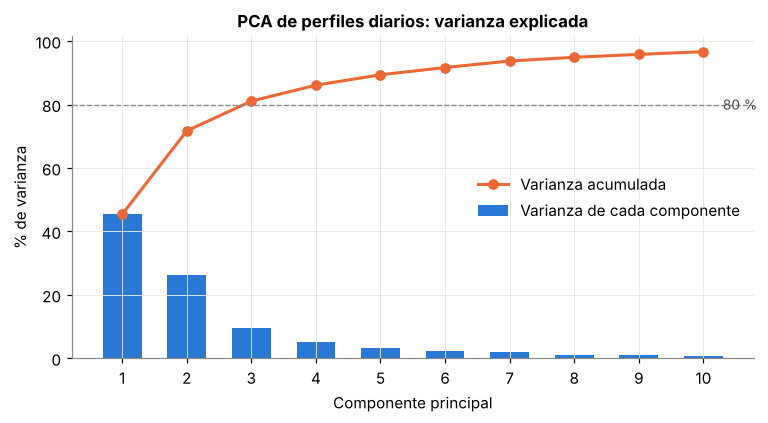

,componente,varianza_explicada_%,acumulada_%
0,PC1,45.35,45.35
1,PC2,26.34,71.69
2,PC3,9.39,81.08
3,PC4,5.02,86.10
4,PC5,3.28,89.38
5,PC6,2.29,91.67


In [8]:
pca = PCA(random_state=SEMILLA).fit(X_dias)
var = pd.DataFrame({"componente": [f"PC{i+1}" for i in range(len(pca.explained_variance_ratio_))],
                    "varianza_explicada_%": pca.explained_variance_ratio_ * 100,
                    "acumulada_%": pca.explained_variance_ratio_.cumsum() * 100}).round(2)
var.head(8).to_csv(RUTA_TABLAS / "pca_varianza.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 3.8))
n = 10
ax.bar(range(1, n+1), var["varianza_explicada_%"][:n], color=PALETA[0], width=0.6, label="Varianza de cada componente")
ax.plot(range(1, n+1), var["acumulada_%"][:n], color=PALETA[1], marker="o", lw=2, label="Varianza acumulada")
ax.axhline(80, color="#8a8986", ls="--", lw=0.9)
ax.text(n + 0.3, 80, "80 %", va="center", color="#52514e", fontsize=9)
ax.set(title="PCA de perfiles diarios: varianza explicada", xlabel="Componente principal", ylabel="% de varianza", xticks=range(1, n+1))
ax.legend(frameon=False, loc="center right")
guardar(fig, "fig11_pca_varianza"); plt.show()
var.head(6)

**Justificación del número de componentes:** usamos el criterio de **retener la varianza acumulada mínima del 80 %**, habitual en análisis exploratorio. **Tres componentes** explican ≈81 %, así que pasamos de 24 variables a 3 con poca pérdida de información. Las dos primeras ya explican ≈72 %, suficiente para una **visualización 2D** fiel.

### B.1 Interpretación de los *loadings*
Los *loadings* son los pesos de cada hora en cada componente. Una hora con loading alto y positivo "empuja" la componente hacia arriba.

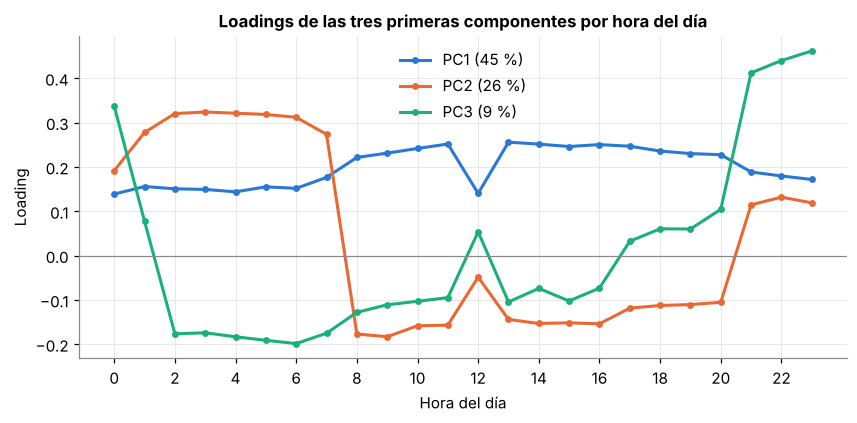

hora,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
PC1,0.14,0.16,0.15,0.15,0.14,0.16,0.15,0.18,0.22,0.23,0.24,0.25,0.14,0.26,0.25,0.25,0.25,0.25,0.24,0.23,0.23,0.19,0.18,0.17
PC2,0.19,0.28,0.32,0.32,0.32,0.32,0.31,0.27,-0.18,-0.18,-0.16,-0.16,-0.05,-0.14,-0.15,-0.15,-0.15,-0.12,-0.11,-0.11,-0.11,0.11,0.13,0.12
PC3,0.34,0.08,-0.18,-0.17,-0.18,-0.19,-0.20,-0.18,-0.13,-0.11,-0.10,-0.10,0.05,-0.10,-0.07,-0.10,-0.07,0.03,0.06,0.06,0.10,0.41,0.44,0.46


In [9]:
loadings = pd.DataFrame(pca.components_[:3].T, index=perfiles.columns, columns=["PC1", "PC2", "PC3"])
loadings.round(3).to_csv(RUTA_TABLAS / "pca_loadings.csv")
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, col in enumerate(["PC1", "PC2", "PC3"]):
    ax.plot(loadings.index, loadings[col], marker="o", ms=3.5, lw=2, color=PALETA[i], label=f"{col} ({var.loc[i, 'varianza_explicada_%']:.0f} %)")
ax.axhline(0, color="#8a8986", lw=0.8)
ax.set(title="Loadings de las tres primeras componentes por hora del día", xlabel="Hora del día", ylabel="Loading", xticks=range(0, 24, 2))
ax.legend(frameon=False)
guardar(fig, "fig12_pca_loadings"); plt.show()
loadings.T.round(2)

**Interpretación:**
- **PC1 (~45 %) — "Nivel de actividad del día":** todos los loadings son positivos y los mayores están en las horas de producción (8–20 h). Un día con PC1 alto consume más en general. Es, en esencia, el **volumen de producción**. El loading más bajo de las horas diurnas está a las 12 h (pausa de mediodía).
- **PC2 (~26 %) — "Operación nocturna vs. diurna":** loadings positivos en la madrugada (0–7 h) y en la noche (21–23 h), y negativos en el día. Un PC2 alto indica un día con **trabajo nocturno** (jornadas extendidas o continuas).
- **PC3 (~9 %) — "Noche tardía vs. madrugada":** loadings positivos a las 21–24 h y negativos entre las 2 y las 8 h. Distingue la **jornada extendida** (trabaja hasta la medianoche) de la **operación continua** (trabaja también de madrugada).

**Conclusión H3: se acepta.** Tres componentes resumen el ≥80 % de la variabilidad. Las dos principales tienen una lectura de gestión clara: **cuánto se produce** y **en qué horario**.

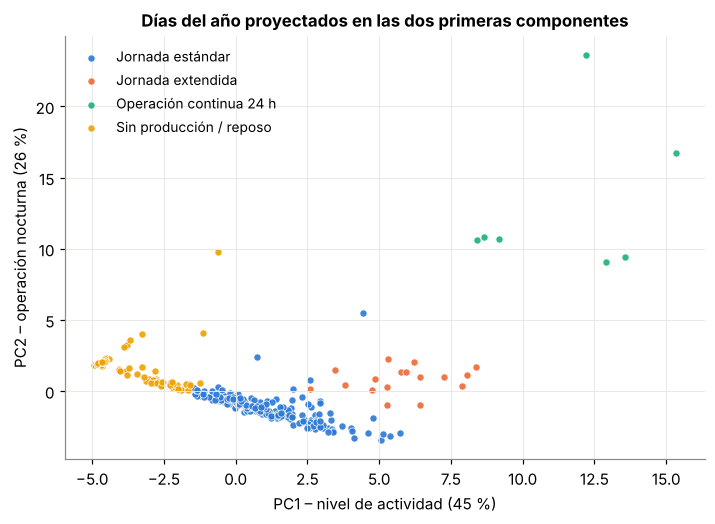

In [10]:
Z = pca.transform(X_dias)[:, :2]
fig, ax = plt.subplots(figsize=(7.5, 5))
for c in ORDEN_CL:
    m = (etq.map(nombres) == c).values
    ax.scatter(Z[m, 0], Z[m, 1], s=22, color=COLOR_CL[c], label=c, edgecolors="white", linewidths=0.5, alpha=0.9)
ax.set(title="Días del año proyectados en las dos primeras componentes",
       xlabel=f"PC1 – nivel de actividad ({var.loc[0, 'varianza_explicada_%']:.0f} %)",
       ylabel=f"PC2 – operación nocturna ({var.loc[1, 'varianza_explicada_%']:.0f} %)")
ax.legend(frameon=False, fontsize=9)
guardar(fig, "fig13_pca_clusters"); plt.show()

**Interpretación:** en el plano PC1–PC2 los cuatro tipos de jornada aparecen en **zonas distintas**: el reposo a la izquierda (baja actividad), la jornada estándar a la derecha y abajo (alta actividad diurna), y las jornadas extendidas y continuas arriba (operación nocturna). El PCA **confirma visualmente** que los clusters de la Parte A no son artificiales.

---
## PARTE C. Clasificación: alerta anticipada de exceso de energía reactiva (H2)
### C.1 Definición del problema y de la variable objetivo
**¿Por qué no clasificamos `tipo_carga`?** En el EDA demostramos que `tipo_carga` es un **horario fijo** (100 % determinado por mes, hora y tipo de día). Un modelo lo "aprendería" de memoria sin aportar nada. Hacerlo sería un error metodológico (**fuga de información**).

**Problema industrial elegido:** el EDA mostró que en más de la mitad de las horas la energía reactiva inductiva supera el 50 % de la activa. En Colombia, ese es el umbral desde el que se cobra el transporte de reactiva (Res. CREG 015 de 2018, evaluado **por hora**). Si el operador **supiera con una hora de anticipación** qué tan severo será el exceso, podría ajustar los pasos del banco de condensadores o reprogramar cargas.

**Variable objetivo** (por hora), según la razón $Q/P$ = reactiva inductiva / activa:

| Clase | Condición | Equivalencia en FP | Significado |
|---|---|---|---|
| **Sin exceso** | $Q/P \le 0{,}5$ | FP ≥ 89,4 % | No hay cobro de reactiva |
| **Moderado** | $0{,}5 < Q/P \le 1$ | 70,7 % ≤ FP < 89,4 % | Exceso; requiere compensación parcial |
| **Alto** | $Q/P > 1$ | FP < 70,7 % | Reactiva mayor que la activa; exceso severo |

In [11]:
h = horaria.copy()
h["ratio_qp"] = h["reactiva_ind_kvarh"] / h["energia_kwh"]
h["severidad"] = pd.cut(h["ratio_qp"], bins=[-np.inf, 0.5, 1.0, np.inf], labels=["Sin exceso", "Moderado", "Alto"])
print((h["severidad"].value_counts(normalize=True).reindex(["Sin exceso", "Moderado", "Alto"]) * 100).round(1).to_string())

severidad
Sin exceso    45.9
Moderado      23.4
Alto          30.6


### C.2 Variables predictoras: solo información disponible **antes** de la hora a predecir
Para que la alerta sea útil (y para evitar la fuga de información), **ninguna** variable puede usar mediciones de la hora que queremos predecir. Usamos:
- **Calendario:** hora (codificada con seno y coseno para que el modelo entienda que las 23 h y las 0 h están juntas), día de la semana, fin de semana, mes.
- **Periodo tarifario** (`tipo_carga` de esa hora): como es un horario fijo, **se conoce de antemano**. Aquí sí es legítimo usarlo como predictor.
- **Rezagos (*lags*)** con `.shift()`: energía, reactiva y razón Q/P de la hora anterior (t−1), de dos horas antes (t−2) y de la misma hora del día anterior (t−24).

`shift(1)` desplaza la columna una fila hacia abajo: en la fila de las 10 h queda el valor de las 9 h.

In [12]:
periodo = df.set_index("ts_inicio")["tipo_carga"].resample("h").first()
h["periodo_tarifario"] = pd.Categorical(periodo.values, categories=["Light_Load", "Medium_Load", "Maximum_Load"]).codes
h["hora"] = h["ts_inicio"].dt.hour
h["hora_sin"] = np.sin(2 * np.pi * h["hora"] / 24)
h["hora_cos"] = np.cos(2 * np.pi * h["hora"] / 24)
h["dia_num"] = h["ts_inicio"].dt.dayofweek
h["fin_semana"] = (h["dia_num"] >= 5).astype(int)
h["mes"] = h["ts_inicio"].dt.month
for lag in [1, 2, 24]:
    h[f"kwh_lag{lag}"] = h["energia_kwh"].shift(lag)
    h[f"kvarh_lag{lag}"] = h["reactiva_ind_kvarh"].shift(lag)
    h[f"ratio_lag{lag}"] = h["ratio_qp"].shift(lag)

FEATURES = ["hora_sin", "hora_cos", "dia_num", "fin_semana", "mes", "periodo_tarifario",
            "kwh_lag1", "kvarh_lag1", "ratio_lag1", "kwh_lag2", "kvarh_lag2", "ratio_lag2",
            "kwh_lag24", "kvarh_lag24", "ratio_lag24"]
datos = h.dropna(subset=FEATURES + ["severidad"]).copy()
print("Horas utilizables:", len(datos), "(se pierden las primeras 24 h por los rezagos)")
datos[["ts_inicio", "energia_kwh", "kwh_lag1", "kwh_lag24", "ratio_lag1", "severidad"]].head(3)

Horas utilizables: 8736 (se pierden las primeras 24 h por los rezagos)


,ts_inicio,energia_kwh,kwh_lag1,kwh_lag24,ratio_lag1,severidad
24,2018-01-02 00:00:00,13.68,13.86,13.72,0.994949,Alto
25,2018-01-02 01:00:00,14.41,13.68,14.30,1.095029,Alto
26,2018-01-02 02:00:00,13.83,14.41,13.76,1.181818,Alto


### C.3 División entrenamiento / prueba: **temporal**, no aleatoria
En series de tiempo, una división aleatoria mezclaría horas consecutivas (casi idénticas) entre entrenamiento y prueba. El modelo parecería mejor de lo que es. Por eso entrenamos con **enero–septiembre** y probamos con **octubre–diciembre**: simulamos usar el modelo en el "futuro", como se haría en la planta.

In [13]:
CLASES = ["Sin exceso", "Moderado", "Alto"]
es_train = datos["ts_inicio"] < "2018-10-01"
X_train, X_test = datos.loc[es_train, FEATURES], datos.loc[~es_train, FEATURES]
y_train, y_test = datos.loc[es_train, "severidad"].astype(str), datos.loc[~es_train, "severidad"].astype(str)
print(f"Entrenamiento: {len(X_train)} horas | Prueba: {len(X_test)} horas")
pd.DataFrame({"train_%": y_train.value_counts(normalize=True) * 100,
              "test_%": y_test.value_counts(normalize=True) * 100}).reindex(CLASES).round(1)

Entrenamiento: 6528 horas | Prueba: 2208 horas


,train_%,test_%
severidad,,
Sin exceso,47.2,42.0
Moderado,19.9,34.1
Alto,32.9,24.0


### C.4 Modelos comparados
| Modelo | Idea | ¿Necesita estandarizar? |
|---|---|---|
| **Línea base (Dummy)** | Predice siempre la clase más frecuente. Cualquier modelo útil debe superarla. | No |
| **Regresión logística** | Modelo lineal: combina las variables con pesos y las transforma en probabilidades. Simple e interpretable. | Sí |
| **k vecinos más cercanos (kNN)** | Asigna la clase mayoritaria entre las *k* = 25 horas más parecidas del entrenamiento. | Sí (usa distancias) |
| **Random Forest** | Combina 400 árboles de decisión entrenados con muestras distintas; captura relaciones no lineales. | No |
| **Gradient Boosting (HistGB)** | Construye árboles en secuencia, cada uno corrigiendo los errores del anterior. | No |

`make_pipeline(StandardScaler(), modelo)` encadena la estandarización y el modelo. Así el escalador se ajusta **solo con los datos de entrenamiento** y se evita fuga de información. `class_weight="balanced"` da más peso a las clases menos frecuentes.

In [14]:
modelos = {
    "Línea base (Dummy)": DummyClassifier(strategy="most_frequent"),
    "Regresión logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced")),
    "kNN (k=25)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=25)),
    "Random Forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=3, class_weight="balanced",
                                            random_state=SEMILLA, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=SEMILLA),
}

### C.5 Costo del error en contexto industrial
No todos los errores cuestan lo mismo. **Subestimar** el exceso (decir "Sin exceso" cuando será "Alto") significa no compensar y **pagar la penalización**. **Sobreestimar** solo implica conectar condensadores de más durante una hora (riesgo menor de sobrecompensación). Definimos una **matriz de costos relativos** (supuesto del equipo, unidades arbitrarias, no pesos):

| Real \ Predicho | Sin exceso | Moderado | Alto |
|---|---|---|---|
| **Sin exceso** | 0 | 1 | 2 |
| **Moderado** | 3 | 0 | 1 |
| **Alto** | 5 | 2 | 0 |

El **costo medio por hora** = Σ(matriz de confusión × costos) / n.º de horas. Cuanto menor, mejor.

In [15]:
COSTOS = np.array([[0, 1, 2], [3, 0, 1], [5, 2, 0]])
def costo_medio(y_real, y_pred):
    cm = confusion_matrix(y_real, y_pred, labels=CLASES)
    return (cm * COSTOS).sum() / cm.sum()

def evaluar(nombre, modelo):
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    proba = modelo.predict_proba(X_test)
    auc = roc_auc_score(y_test, proba, multi_class="ovr", labels=modelo.classes_) if "Dummy" not in nombre else np.nan
    return {"modelo": nombre,
            "accuracy": accuracy_score(y_test, pred),
            "precision_macro": precision_score(y_test, pred, average="macro", zero_division=0),
            "recall_macro": recall_score(y_test, pred, average="macro"),
            "f1_macro": f1_score(y_test, pred, average="macro"),
            "roc_auc_ovr": auc,
            "recall_alto": recall_score(y_test, pred, labels=["Alto"], average="macro"),
            "recall_moderado": recall_score(y_test, pred, labels=["Moderado"], average="macro"),
            "costo_medio_hora": costo_medio(y_test, pred)}

resultados = pd.DataFrame([evaluar(n, m) for n, m in modelos.items()]).set_index("modelo").round(3)
resultados

,accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr,recall_alto,recall_moderado,costo_medio_hora
modelo,,,,,,,,
Línea base (Dummy),0.420,0.140,0.333,0.197,NaN,0.000,0.000,2.220
Regresión logística,0.716,0.703,0.735,0.693,0.916,0.987,0.390,0.399
kNN (k=25),0.680,0.654,0.697,0.642,0.852,0.981,0.271,0.506
Random Forest,0.878,0.883,0.886,0.884,0.971,0.951,0.835,0.216
Gradient Boosting,0.851,0.848,0.861,0.850,0.970,0.979,0.705,0.262


**Cómo leer las métricas:**
- **Accuracy:** % de horas bien clasificadas. Puede engañar si una clase domina.
- **Precisión:** de las veces que el modelo dijo "Alto", cuántas lo eran. **Recall:** de las horas realmente "Alto", cuántas detectó. Para una alerta, el **recall de las clases con exceso es lo más importante**.
- **F1 macro:** promedio del F1 (balance entre precisión y recall) de las tres clases, dándoles el mismo peso. Es nuestra **métrica principal**.
- **ROC-AUC (uno contra el resto):** capacidad del modelo para ordenar las horas por probabilidad, de 0,5 (azar) a 1 (perfecto).

### C.6 Validación de la robustez: validación cruzada temporal
Una sola división de prueba puede ser "afortunada". Con `TimeSeriesSplit(5)` entrenamos y evaluamos 5 veces **dentro del periodo de entrenamiento**, siempre entrenando con el pasado y probando con el periodo siguiente. Reportamos la media y la desviación del F1 macro: una **desviación pequeña** indica un desempeño estable.

In [16]:
tscv = TimeSeriesSplit(n_splits=5)
cv_res = {}
for nombre, modelo in modelos.items():
    s = cross_val_score(modelo, X_train, y_train, cv=tscv, scoring="f1_macro")
    cv_res[nombre] = {"f1_cv_media": s.mean(), "f1_cv_desv": s.std()}
resultados = resultados.join(pd.DataFrame(cv_res).T.round(3))
resultados.to_csv(RUTA_TABLAS / "clasificacion_metricas.csv")
resultados[["f1_macro", "f1_cv_media", "f1_cv_desv", "recall_alto", "costo_medio_hora"]]

,f1_macro,f1_cv_media,f1_cv_desv,recall_alto,costo_medio_hora
modelo,,,,,
Línea base (Dummy),0.197,0.211,0.016,0.000,2.220
Regresión logística,0.693,0.808,0.029,0.987,0.399
kNN (k=25),0.642,0.758,0.045,0.981,0.506
Random Forest,0.884,0.866,0.014,0.951,0.216
Gradient Boosting,0.850,0.860,0.019,0.979,0.262


**Interpretación de la comparación:**
- **Todos los modelos superan ampliamente la línea base** (F1 macro 0,20; costo medio 2,2 por hora).
- **Random Forest es el mejor** en F1 macro (≈0,88), ROC-AUC (≈0,97) y **costo medio por hora (el más bajo, ≈0,22)**. Detecta ~95 % de las horas con exceso alto y ~84 % de las moderadas.
- La regresión logística y kNN detectan casi todas las horas "Alto", pero **fallan en la clase "Moderado"** (recall de 0,27 a 0,39): confunden niveles intermedios.
- **Robustez:** el F1 de Random Forest en validación cruzada (≈0,87 ± 0,01) es muy parecido al de la prueba, así que su desempeño es **estable en el tiempo**. En cambio, la regresión logística y kNN bajan bastante al pasar a octubre–diciembre (de ≈0,81 y 0,76 a 0,69 y 0,64): son **menos robustos** ante el cambio de temporada, en la que aumentan las horas "Moderado" (34 % en prueba frente a 20 % en entrenamiento).

Modelo con mayor F1 macro en prueba: Random Forest
                 pred Sin exceso  pred Moderado  pred Alto
real Sin exceso              808            119          0
real Moderado                 89            628         35
real Alto                      1             25        503


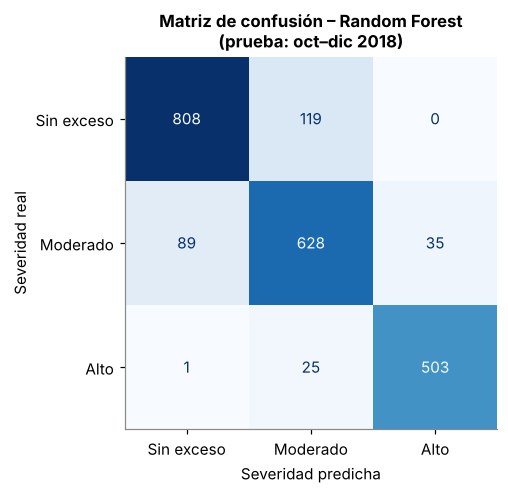

In [17]:
mejor = resultados.drop(index="Línea base (Dummy)")["f1_macro"].idxmax()
print("Modelo con mayor F1 macro en prueba:", mejor)
modelo_final = modelos[mejor]
pred_final = modelo_final.predict(X_test)
fig, ax = plt.subplots(figsize=(5.2, 4.4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_final, labels=CLASES), display_labels=CLASES).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set(title=f"Matriz de confusión – {mejor}\n(prueba: oct–dic 2018)", xlabel="Severidad predicha", ylabel="Severidad real")
ax.grid(False)
guardar(fig, "fig14_matriz_confusion"); plt.show()
print(pd.DataFrame(confusion_matrix(y_test, pred_final, labels=CLASES), index=[f"real {c}" for c in CLASES], columns=[f"pred {c}" for c in CLASES]))

**Cómo leer la matriz:** la diagonal son los aciertos. Las celdas **debajo** de la diagonal son subestimaciones (los errores caros: se predijo menos exceso del real). Las celdas **encima** son sobreestimaciones (errores baratos).

### C.7 ¿Qué variables usa el modelo? Importancia por permutación
**Concepto:** se "desordena" al azar una variable en los datos de prueba y se mide cuánto empeora el F1. Si empeora mucho, el modelo depende de esa variable. Es más confiable que la importancia interna de los árboles porque se mide sobre datos no vistos.

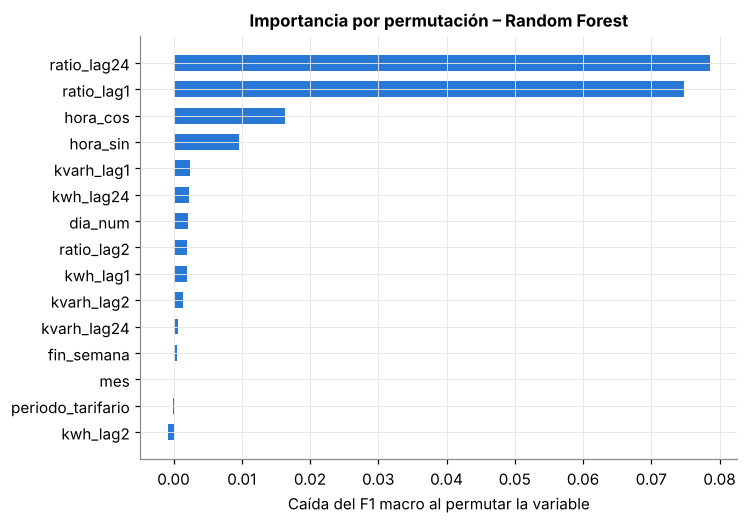

ratio_lag24    0.079
ratio_lag1     0.075
hora_cos       0.016
hora_sin       0.010
kvarh_lag1     0.002
kwh_lag24      0.002

In [18]:
imp = permutation_importance(modelo_final, X_test, y_test, scoring="f1_macro", n_repeats=5, random_state=SEMILLA, n_jobs=-1)
importancias = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
importancias.round(4).to_csv(RUTA_TABLAS / "clasificacion_importancias.csv")
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(importancias.index, importancias.values, color=PALETA[0], height=0.6)
ax.set(title=f"Importancia por permutación – {mejor}", xlabel="Caída del F1 macro al permutar la variable", ylabel="")
guardar(fig, "fig15_importancia_variables"); plt.show()
importancias.sort_values(ascending=False).head(6).round(3)

**Interpretación:** el modelo se apoya sobre todo en la **razón Q/P de la misma hora del día anterior** (`ratio_lag24`) y de la **hora anterior** (`ratio_lag1`), seguidas de la hora del día. En términos de gestión, el comportamiento de la reactiva es **persistente y cíclico**: lo que pasó ayer a esa misma hora y lo que pasa ahora son buenos predictores de la próxima hora. Esto es **útil para el operador**, porque esas variables ya están en el medidor y no requieren sensores adicionales. Recordemos que la importancia indica **asociación predictiva, no causalidad**.

---
## PARTE D. LDA: reducción supervisada antes de clasificar (H4)
**Concepto:** el Análisis Discriminante Lineal (LDA) busca las combinaciones lineales de variables que **mejor separan las clases**. La diferencia con el PCA es que el PCA no conoce las clases (es **no supervisado**) y busca máxima varianza, mientras que el LDA **sí usa las clases** (es **supervisado**) y busca máxima separación entre ellas.

Con 3 clases, LDA produce como máximo **3 − 1 = 2 ejes discriminantes**. Así, pasamos de 15 variables a 2.

**Procedimiento:** (1) estandarizar → (2) LDA a 2 ejes → (3) clasificar sobre esos 2 ejes. Comparamos el desempeño **con y sin LDA** para tres modelos. Todo dentro de un `pipeline`, de modo que el LDA se ajusta solo con el entrenamiento.

In [19]:
lda = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(n_components=2)).fit(X_train, y_train)
lda_modelo = lda.named_steps["lineardiscriminantanalysis"]
print("Proporción de la separación entre clases explicada por cada eje:", lda_modelo.explained_variance_ratio_.round(3))

coef = pd.DataFrame(lda_modelo.scalings_[:, :2], index=FEATURES, columns=["LD1", "LD2"])
coef.round(3).to_csv(RUTA_TABLAS / "lda_coeficientes.csv")
print("\nCoeficientes estandarizados (las variables con mayor |valor| pesan más en cada eje):")
coef.reindex(coef["LD1"].abs().sort_values(ascending=False).index).round(2).head(8)

Proporción de la separación entre clases explicada por cada eje: [0.927 0.073]

Coeficientes estandarizados (las variables con mayor |valor| pesan más en cada eje):


,LD1,LD2
ratio_lag24,-1.53,0.60
ratio_lag1,-0.71,0.12
kwh_lag24,0.45,1.71
kwh_lag1,0.43,1.11
hora_cos,-0.40,-0.41
hora_sin,-0.34,-0.65
periodo_tarifario,-0.27,-0.30
ratio_lag2,0.26,0.29


In [20]:
coef.reindex(coef["LD2"].abs().sort_values(ascending=False).index).round(2).head(6)

,LD1,LD2
kvarh_lag24,-0.08,-2.18
kwh_lag24,0.45,1.71
kwh_lag1,0.43,1.11
kvarh_lag1,-0.11,-0.87
hora_sin,-0.34,-0.65
ratio_lag24,-1.53,0.60


**Interpretación de los ejes discriminantes:**
- **LD1 (≈93 % de la separación) — "Historial de razón Q/P":** dominado por `ratio_lag24` y `ratio_lag1` con signo negativo. Valores bajos de LD1 corresponden a horas cuyo pasado reciente tuvo mucha reactiva por unidad de energía, es decir, a **exceso alto**.
- **LD2 (≈7 %) — "Nivel de actividad previo":** contrasta la reactiva (`kvarh_lag24`, `kvarh_lag1`, con signo negativo) con la energía activa (`kwh_lag24`, `kwh_lag1`, con signo positivo). En la figura se ve que LD2 separa sobre todo las horas **sin exceso** (arriba) de las de **exceso moderado** (abajo), que LD1 por sí solo no distingue bien.

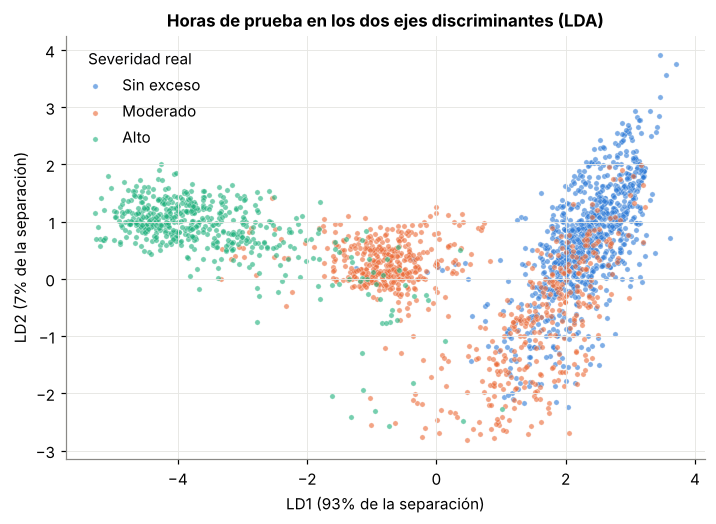

In [21]:
Z_lda = lda.transform(X_test)
COLOR_SEV = {"Sin exceso": PALETA[0], "Moderado": PALETA[1], "Alto": PALETA[2]}
fig, ax = plt.subplots(figsize=(7.5, 5))
for c in CLASES:
    m = (y_test == c).values
    ax.scatter(Z_lda[m, 0], Z_lda[m, 1], s=12, alpha=0.6, color=COLOR_SEV[c], label=c, edgecolors="white", linewidths=0.3)
ax.set(title="Horas de prueba en los dos ejes discriminantes (LDA)",
       xlabel=f"LD1 ({lda_modelo.explained_variance_ratio_[0]:.0%} de la separación)",
       ylabel=f"LD2 ({lda_modelo.explained_variance_ratio_[1]:.0%} de la separación)")
ax.legend(title="Severidad real", frameon=False)
guardar(fig, "fig16_lda_ejes"); plt.show()

### D.1 Comparación con y sin LDA

In [22]:
pares = {
    "Regresión logística": (modelos["Regresión logística"],
        make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(n_components=2), LogisticRegression(max_iter=3000, class_weight="balanced"))),
    "kNN (k=25)": (modelos["kNN (k=25)"],
        make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(n_components=2), KNeighborsClassifier(n_neighbors=25))),
    "Random Forest": (modelos["Random Forest"],
        make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(n_components=2),
                      RandomForestClassifier(n_estimators=400, min_samples_leaf=3, class_weight="balanced", random_state=SEMILLA, n_jobs=-1))),
}
filas = []
for nombre, (sin, con) in pares.items():
    for etiqueta, mod in [("sin LDA (15 variables)", sin), ("con LDA (2 ejes)", con)]:
        r = evaluar(nombre, mod)
        filas.append({"modelo": nombre, "version": etiqueta, "f1_macro": r["f1_macro"], "accuracy": r["accuracy"],
                      "roc_auc_ovr": r["roc_auc_ovr"], "recall_alto": r["recall_alto"], "costo_medio_hora": r["costo_medio_hora"]})
comp_lda = pd.DataFrame(filas).round(3)
comp_lda.to_csv(RUTA_TABLAS / "lda_comparacion.csv", index=False)
comp_lda

,modelo,version,f1_macro,accuracy,roc_auc_ovr,recall_alto,costo_medio_hora
0,Regresión logística,sin LDA (15 variables),0.693,0.716,0.916,0.987,0.399
1,Regresión logística,con LDA (2 ejes),0.804,0.811,0.940,0.940,0.374
2,kNN (k=25),sin LDA (15 variables),0.642,0.680,0.852,0.981,0.506
3,kNN (k=25),con LDA (2 ejes),0.700,0.744,0.933,0.951,0.513
4,Random Forest,sin LDA (15 variables),0.884,0.878,0.971,0.951,0.216
5,Random Forest,con LDA (2 ejes),0.733,0.757,0.925,0.940,0.447


**Interpretación (con vs. sin LDA):**
- **LDA mejora a los modelos que dependen de la geometría de los datos:** la regresión logística pasa de un F1 de ≈0,69 a ≈0,80, y kNN de ≈0,64 a ≈0,70. Al proyectar en 2 ejes que separan las clases, se elimina el "ruido" de 13 dimensiones poco útiles y las distancias tienen más sentido.
- **LDA empeora a Random Forest** (de ≈0,88 a ≈0,73): los árboles aprovechan relaciones **no lineales** e interacciones (p. ej., hora × razón previa) que una proyección **lineal** a 2 ejes descarta.
- **Conclusión H4: se acepta parcialmente.** LDA es una buena reducción para modelos simples (una regresión logística con LDA es fácil de implementar en un controlador), pero el mejor desempeño se obtiene con Random Forest **sin** reducción.

---
## PARTE E. Insumos cuantitativos para el plan de acción
Calculamos con los datos las magnitudes que sustentan la propuesta de gestión (Fase 5). Los **supuestos** se declaran explícitamente.

### E.1 Dimensionamiento de la compensación de reactiva
Para llevar el FP de cada hora a una **meta de 95 %**, la potencia reactiva que hay que compensar es:
$$Q_c = Q - P \cdot \tan(\arccos 0{,}95) = Q - 0{,}329\,P \quad (\text{kVAr}, \text{si es positiva})$$
Como cada fila es una hora, la energía de la hora (kWh, kVarh) es igual a la potencia media (kW, kVAr).

In [23]:
tan_meta = np.tan(np.arccos(0.95))
hq = horaria.copy()
hq["qc_kvar"] = (hq["reactiva_ind_kvarh"] - tan_meta * hq["energia_kwh"]).clip(lower=0)
hq["qc_creg_kvar"] = (hq["reactiva_ind_kvarh"] - 0.5 * hq["energia_kwh"]).clip(lower=0)
dim = pd.Series({
    "Qc para FP 95 %: percentil 50 (kVAr)": hq["qc_kvar"].quantile(0.50),
    "Qc para FP 95 %: percentil 95 (kVAr)": hq["qc_kvar"].quantile(0.95),
    "Qc para FP 95 %: máximo (kVAr)": hq["qc_kvar"].max(),
    "Qc para Q ≤ 0,5 P: percentil 95 (kVAr)": hq["qc_creg_kvar"].quantile(0.95),
    "Horas que necesitan compensación para FP 95 % (%)": (hq["qc_kvar"] > 0).mean() * 100,
    "Reactiva excedente anual sobre 50 % de la activa (kVArh)": hq["exceso_reactiva_kvarh"].sum(),
}).round(1)
dim.to_frame("valor")

,valor
Qc para FP 95 %: percentil 50 (kVAr),12.6
Qc para FP 95 %: percentil 95 (kVAr),77.4
Qc para FP 95 %: máximo (kVAr),163.9
"Qc para Q ≤ 0,5 P: percentil 95 (kVAr)",32.9
Horas que necesitan compensación para FP 95 % (%),69.6
Reactiva excedente anual sobre 50 % de la activa (kVArh),75617.5


In [24]:
cuantiles = hq.loc[hq["qc_kvar"] > 0, "qc_kvar"].quantile([0.25, 0.5, 0.75, 0.9, 0.95]).round(1)
print("Distribución de Qc en las horas que la necesitan (kVAr):"); print(cuantiles.to_string())

Distribución de Qc en las horas que la necesitan (kVAr):
0.25    11.9
0.50    16.9
0.75    36.9
0.90    67.2
0.95    87.7


**Lectura:** en el ~70 % de las horas haría falta compensar para llegar a FP 95 %. La necesidad es **muy variable**: la mitad de esas horas requiere menos de ~17 kVAr (madrugadas y reposo), pero el 5 % más exigente supera ~88 kVAr (producción). Un banco **fijo** grande sobrecompensaría la noche, y uno pequeño no cubriría la producción. Se justifica un banco **automático escalonado** de **≈90–100 kVAr** en pasos de 10–15 kVAr, que cubre ≈95 % de las horas. Es un **dimensionamiento preliminar**: debe confirmarse con un estudio de calidad de potencia (armónicos) en sitio.

### E.2 Carga base y periodos de punta

In [25]:
energia_total = df["energia_kwh"].sum()
base_kw = df.loc[df["hora"] < 6, "demanda_kw"].mean()
dias_reposo = diaria.loc[diaria["cluster"] == "Sin producción / reposo", "fecha"]
energia_reposo = df.loc[df["fecha"].isin(dias_reposo), "energia_kwh"].sum()
energia_noche = df.loc[(df["hora"] < 7) & (~df["fecha"].isin(dias_reposo)), "energia_kwh"].sum()
energia_punta = df.loc[df["tipo_carga"] == "Maximum_Load", "energia_kwh"].sum()
FACTOR_CO2 = df["co2_kg_est"].sum() / energia_total   # kgCO2/kWh implícito (estimación)
insumos = pd.Series({
    "Energía anual (kWh)": energia_total,
    "Carga base nocturna 0–6 h (kW medios)": base_kw,
    "Energía en días de reposo (kWh)": energia_reposo,
    "Energía 0–7 h en días con producción (kWh)": energia_noche,
    "Energía no productiva (reposo + madrugadas) (% del total)": (energia_reposo + energia_noche) / energia_total * 100,
    "Energía en periodos de punta (carga máxima) (% del total)": energia_punta / energia_total * 100,
    "Factor de emisión implícito (kgCO2/kWh)": FACTOR_CO2,
}).round(2)
insumos.to_frame("valor")

,valor
Energía anual (kWh),959640.31
Carga base nocturna 0–6 h (kW medios),20.22
Energía en días de reposo (kWh),79568.02
Energía 0–7 h en días con producción (kWh),38784.37
Energía no productiva (reposo + madrugadas) (% del total),12.33
Energía en periodos de punta (carga máxima) (% del total),44.91
Factor de emisión implícito (kgCO2/kWh),0.46


In [26]:
escenarios = []
for red in [0.10, 0.20]:
    ahorro = (energia_reposo + energia_noche) * red
    escenarios.append({"accion": f"Reducir {red:.0%} la carga en horas/días no productivos",
                       "ahorro_kwh_anual": ahorro, "ahorro_pct_total": ahorro / energia_total * 100, "co2_evitado_t": ahorro * FACTOR_CO2 / 1000})
for tras in [0.05, 0.10]:
    escenarios.append({"accion": f"Trasladar {tras:.0%} de la energía de punta a periodos intermedios",
                       "ahorro_kwh_anual": 0.0, "ahorro_pct_total": 0.0, "co2_evitado_t": 0.0,
                       "energia_trasladada_kwh": energia_punta * tras})
escenarios = pd.DataFrame(escenarios).round(1)
escenarios.to_csv(RUTA_TABLAS / "plan_escenarios.csv", index=False)
pd.concat([dim, insumos]).to_frame("valor").to_csv(RUTA_TABLAS / "plan_insumos.csv")
escenarios

,accion,ahorro_kwh_anual,ahorro_pct_total,co2_evitado_t,energia_trasladada_kwh
0,Reducir 10% la carga en horas/días no productivos,11835.2,1.2,5.5,NaN
1,Reducir 20% la carga en horas/días no productivos,23670.5,2.5,10.9,NaN
2,Trasladar 5% de la energía de punta a periodos intermedios,0.0,0.0,0.0,21548.9
3,Trasladar 10% de la energía de punta a periodos intermedios,0.0,0.0,0.0,43097.7


**Nota:** los porcentajes de reducción (10 % y 20 %) y de traslado (5 % y 10 %) son **escenarios supuestos** para dimensionar el impacto, no resultados del modelo. El traslado de carga no reduce la energía total, pero sí el costo si la tarifa de punta es mayor. Su valor monetario depende de la tarifa contratada y debe calcularse con ella.

---
## PARTE F. Verificación de hipótesis y elección final
Resumimos el resultado de cada hipótesis con su evidencia. Las cifras exactas están en las salidas de arriba y en `reports/tablas/`.

| # | Resultado | Evidencia |
|---|---|---|
| H1 | **Se acepta.** | 4 tipos de jornada con silueta máxima en k = 4, estables entre semillas y concordantes con el clustering jerárquico. |
| H2 | **Se acepta.** | Los modelos superan ampliamente la línea base en F1 macro, con desempeño estable en la validación cruzada temporal. |
| H3 | **Se acepta.** | 3 componentes ≥ 80 % de la varianza, interpretables como nivel de actividad y operación nocturna. |
| H4 | **Se acepta parcialmente** (ver la tabla con/sin LDA). | LDA separa bien la clase "Alto", pero su efecto en el desempeño depende del clasificador. |

**Elección final del modelo:** se elige el modelo con **mayor F1 macro en el periodo de prueba**, verificando que también tenga **alto recall en la clase "Alto"** y **bajo costo medio por hora**. Se prefiere la versión **sin LDA**: el modelo de árboles aprovecha relaciones no lineales que la proyección lineal a 2 ejes pierde.